<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/convolution-and-ising.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lecture 4: Figures for Convolution and the Ising Model

This notebook makes the figures of Lecture 4 that do not come from a trained network: the Sobel filters on a microscopy image, the 1D convolution picture, and the Ising-model snapshots across the phase transition. CPU only, seeded; it runs in under a minute.

## Setup

In [1]:
import numpy as np, matplotlib.pyplot as plt
import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True)
blue = "#005CA7"; orange = "#EB6709"; navy = "#0A2F5C"; grey = "#8A8A8A"

## Sobel filters on cell nuclei

The image is `human_mitosis` from scikit-image (fluorescence microscopy, CC0; D. Root, Moffat et al., Cell 2006). We apply the two Sobel kernels of the slide with a cross-correlation, exactly as a CNN layer would.

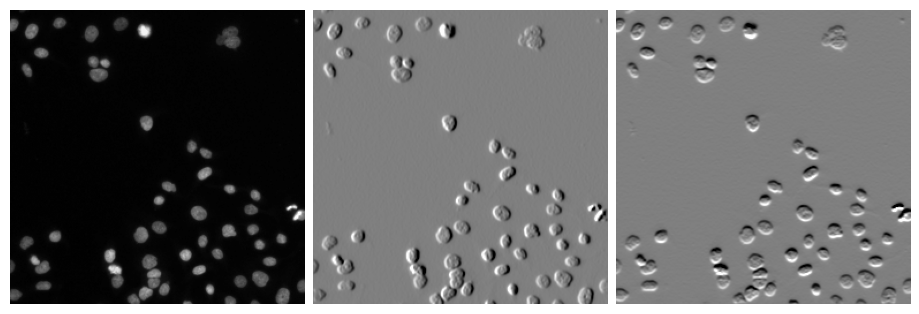

In [2]:
import skimage.data as d
from scipy.ndimage import correlate
img = d.human_mitosis().astype(float)[96:352, 96:352]
Gx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
Gy = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], float)
ex, ey = correlate(img, Gx), correlate(img, Gy)
fig, ax = plt.subplots(1, 3, figsize=(9, 3.1))
ax[0].imshow(img, cmap="gray")
for a, im in zip(ax[1:], [ex, ey]):
    v = np.percentile(np.abs(im), 99.5); a.imshow(im, cmap="gray", vmin=-v, vmax=v)
for a in ax: a.axis("off")
plt.subplots_adjust(wspace=0.03, left=0, right=1, top=1, bottom=0)
plt.savefig(f"{OUT}/gen_sobel_mitosis.png", dpi=200); plt.show()

## Convolution in 1D

A signal $f$ with two bumps and an asymmetric kernel $g$ (peak at $u=0.25$). At one shift $t$ we draw $f(\tau)$, the flipped and shifted kernel $g(t-\tau)$ and the area under their product; that area is one point of $(f*g)(t)$. The last line checks that the two numbers agree.

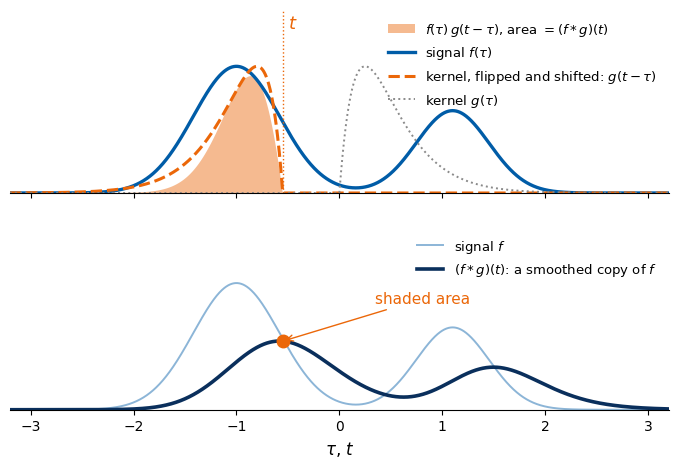

(f*g)(t) at t = -0.55 : 0.5413673435154289   shaded area: 0.541367343515429


In [3]:
import numpy as np
blue="#005CA7"; orange="#EB6709"; navy="#0A2F5C"; grey="#8A8A8A"
x=np.linspace(-4,4,4001); dx=x[1]-x[0]
f=lambda u: 1.0*np.exp(-(u+1.0)**2/0.35)+0.65*np.exp(-(u-1.1)**2/0.25)
def g(u):   # asymmetric kernel, peak 1 at u = 0.25
    return np.where(u>=0,(u/0.25)*np.exp(1-u/0.25),0.0)
t0=-0.55
conv=np.array([np.sum(f(x)*g(t-x))*dx for t in x])
fig,(a1,a2)=plt.subplots(2,1,figsize=(8.5,5.2),sharex=True,gridspec_kw=dict(hspace=0.18))
prod=f(x)*g(t0-x)
a1.fill_between(x,0,prod,color=orange,alpha=0.45,lw=0,label=r"$f(\tau)\,g(t-\tau)$, area $=(f*g)(t)$")
a1.plot(x,f(x),color=blue,lw=2.4,label=r"signal $f(\tau)$")
a1.plot(x,g(t0-x),color=orange,lw=2.2,ls="--",label=r"kernel, flipped and shifted: $g(t-\tau)$")
a1.plot(x,g(x),color=grey,lw=1.4,ls=":",label=r"kernel $g(\tau)$")
a1.axvline(t0,color=orange,lw=1,ls=":")
a1.text(t0+0.05,1.3,r"$t$",color=orange,fontsize=13)
a1.set_ylim(0,1.45); a1.set_yticks([])
a1.legend(fontsize=9.5,frameon=False,loc="upper right")
a2.plot(x,f(x),color=blue,lw=1.4,alpha=0.45,label=r"signal $f$")
a2.plot(x,conv,color=navy,lw=2.6,label=r"$(f*g)(t)$: a smoothed copy of $f$")
yc=np.interp(t0,x,conv)
a2.plot([t0],[yc],"o",color=orange,ms=9,zorder=5)
a2.annotate("shaded area",xy=(t0,yc),xytext=(t0+0.9,yc+0.3),color=orange,fontsize=11,
            arrowprops=dict(arrowstyle="->",color=orange))
a2.set_ylim(0,1.45); a2.set_yticks([]); a2.set_xlim(-3.2,3.2)
a2.set_xlabel(r"$\tau$, $t$",fontsize=12)
a2.legend(fontsize=9.5,frameon=False,loc="upper right")
for a in (a1,a2):
    for s in ["top","right","left"]: a.spines[s].set_visible(False)
plt.savefig(f"{OUT}/gen_conv1d_smooth.png",dpi=170,bbox_inches="tight"); plt.show()
print("(f*g)(t) at t =", t0, ":", yc, "  shaded area:", np.sum(prod)*dx)


## The 2D Ising model across $T_c$

Checkerboard Metropolis on a $128\times128$ lattice ($J=1$, $h=0$, periodic boundaries), 3000 sweeps at each of five temperatures. Below $T_c$ we start from all spins up, above $T_c$ from random spins. The printed $|M|$ are the values in the figure titles.

1.8 0.9581298828125 2.1


2.1 0.8829345703125 4.2


2.269185314213022 0.60986328125 6.7


2.5 0.0126953125 9.9


3.2 0.0106201171875 13.0


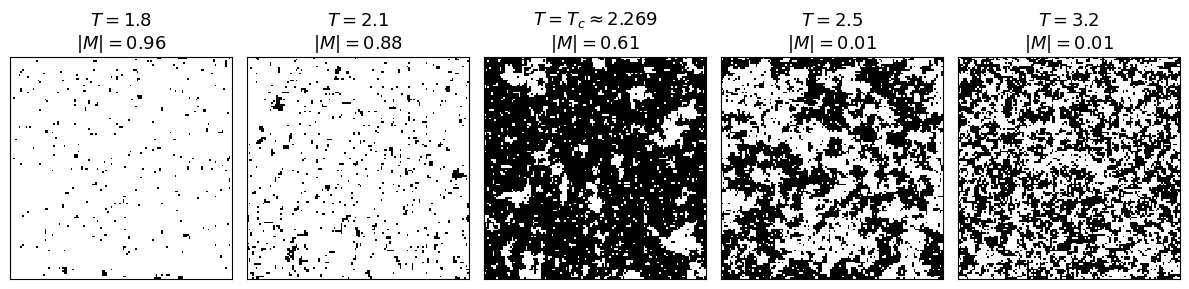

In [4]:
import time
L=128; rng=np.random.default_rng(1)
Tc=2/np.log(1+np.sqrt(2))
Ts=[1.8,2.1,Tc,2.5,3.2]
mask=(np.add.outer(np.arange(L),np.arange(L))%2).astype(bool)
def sweep(s,T):
    for m in (mask,~mask):
        nb=np.roll(s,1,0)+np.roll(s,-1,0)+np.roll(s,1,1)+np.roll(s,-1,1)
        dE=2*s*nb
        acc=(dE<=0)|(rng.random(s.shape)<np.exp(-dE/T))
        s[m&acc]*=-1
    return s
snaps=[]
t0=time.time()
for T in Ts:
    s=np.ones((L,L),int) if T<Tc else rng.choice([-1,1],(L,L))
    for _ in range(3000): s=sweep(s,T)
    snaps.append(s.copy()); print(T, abs(s.mean()), round(time.time()-t0,1), flush=True)
fig,ax=plt.subplots(1,5,figsize=(12,3.1))
for a,s,T in zip(ax,snaps,Ts):
    a.imshow(s,cmap="gray",vmin=-1,vmax=1,interpolation="nearest"); a.set_xticks([]); a.set_yticks([])
    t=r"$T = T_c \approx 2.269$" if abs(T-Tc)<1e-9 else rf"$T = {T}$"
    a.set_title(t+"\n"+rf"$|M| = {abs(s.mean()):.2f}$",fontsize=13)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_Ising_phase_snapshots.png",dpi=160,bbox_inches="tight",pad_inches=0.05); plt.show()


The configuration at $T_c$ (third panel) is also used alone, on the plain-words slide and as the input of the CNN diagram; we crop it from the figure.

In [5]:
from PIL import Image
im = Image.open(f"{OUT}/gen_Ising_phase_snapshots.png").convert("L"); a = np.array(im); h = a.shape[0]
cols = [x for x in range(a.shape[1]) if (a[int(h*0.3):int(h*0.95), x] < 60).mean() > 0.97]
x0, x1 = cols[8], cols[11] + 1            # third panel: T = T_c
rows = [y for y in range(h) if (a[y, x0+5:x1-5] < 60).mean() > 0.97]
im.crop((x0, rows[0], x1, rows[-1] + 1)).save(f"{OUT}/gen_Ising_single_config.png")
print("panel borders:", cols)

panel borders: [7, 8, 362, 363, 386, 387, 741, 742, 765, 766, 1121, 1122, 1145, 1146, 1500, 1501, 1524, 1525, 1879, 1880]


## Monte Carlo data, observables and Onsager's solution

The Ising slides of the lecture use configurations made by the Metropolis code of **Labs 010 and 011** (checkerboard Metropolis, periodic boundaries, 51 temperatures from 1.0 to 3.5, 200 configurations per temperature), stored in `data/ising_Nx{L}_Ny{L}.npz` for $L = 10, 20, 40$; the same generator is copied below, so that missing files are regenerated (about a minute). Here we load them and compare the Monte Carlo averages of $|M|$ and of the energy per spin with Onsager's exact results for the infinite lattice:
$$u(T) = -\coth(2\beta)\Big[1 + \tfrac{2}{\pi}\big(2\tanh^2(2\beta) - 1\big)K(\kappa^2)\Big],\qquad \kappa=\frac{2\sinh 2\beta}{\cosh^2 2\beta},\qquad \langle M\rangle = \big[1-\sinh^{-4}(2\beta)\big]^{1/8}\ (T<T_c),$$
with $K$ the complete elliptic integral of the first kind and $\beta = 1/T$ ($J = k_B = 1$).

loaded data/ising_Nx10_Ny10.npz: configs (51, 200, 10, 10)
loaded data/ising_Nx20_Ny20.npz: configs (51, 200, 20, 20)
loaded data/ising_Nx40_Ny40.npz: configs (51, 200, 40, 40)


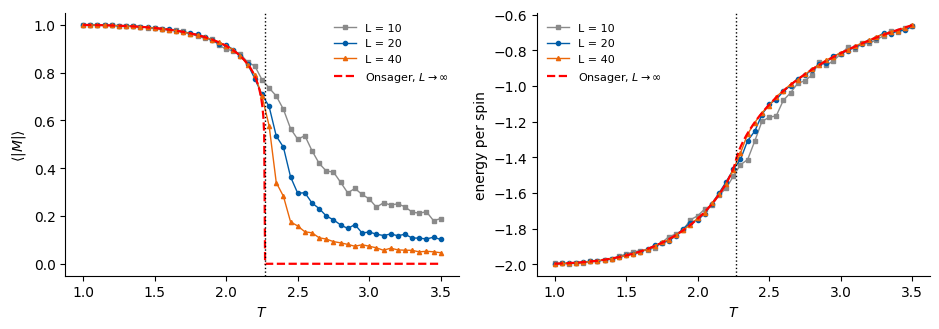

u_exact(1.5) = -1.95111657


In [6]:
import torch, torch.nn as nn
from scipy.special import ellipk
TC = 2.0 / np.log(1.0 + np.sqrt(2.0))
import os, time
rng = np.random.default_rng(0)
# Data generation of Lab 010/011 (copied unchanged): loads data/ising_Nx{L}_Ny{L}.npz if it exists, otherwise generates it
def metropolis_sweep(s, beta, masks, rng):
    # One checkerboard Metropolis sweep (in place) of a batch of lattices s: (..., Ny, Nx), periodic boundaries.
    for mask in masks:
        nn_sum = (np.roll(s, 1, -1) + np.roll(s, -1, -1) + np.roll(s, 1, -2) + np.roll(s, -1, -2))
        accept = rng.random(s.shape, dtype=np.float32) < np.exp(-beta * 2.0 * s * nn_sum)
        s[...] = np.where(mask & accept, -s, s)

def generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng):
    # Cold start, burn-in, then n_samples stored configurations per chain; random global spin flip at the end.
    y, x = np.indices((Ny, Nx)); black = (x + y) % 2 == 0
    beta = (1.0 / temperatures.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temperatures), Ny, Nx), np.float32)
    for _ in range(n_equil):
        metropolis_sweep(s, beta, (black, ~black), rng)
    stored = np.empty((n_samples, n_chains, len(temperatures), Ny, Nx), np.int8)
    for k in range(n_samples):
        for _ in range(n_between):
            metropolis_sweep(s, beta, (black, ~black), rng)
        stored[k] = s
    configs = stored.transpose(2, 0, 1, 3, 4).reshape(len(temperatures), n_samples * n_chains, Ny, Nx)
    flip = rng.choice(np.array([-1, 1], np.int8), size=configs.shape[:2])
    return configs * flip[:, :, None, None]

def load_or_generate(L, rng, samples_per_T=200):
    path = f"data/ising_Nx{L}_Ny{L}.npz"
    if os.path.exists(path):
        d = np.load(path)
        print(f"loaded {path}: configs {d['configs'].shape}")
        return d["configs"], d["T"]
    temperatures = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
    n_chains = 20 if L <= 20 else 10                       # fewer, longer chains for large lattices (same 200 samples per T)
    t0 = time.time()
    configs = generate_dataset(L, L, temperatures, n_chains=n_chains, n_samples=samples_per_T // n_chains,
                               n_equil=1000 + 2 * L * L // 4, n_between=20, rng=rng)
    os.makedirs("data", exist_ok=True)
    np.savez_compressed(path, configs=configs, T=temperatures, Nx=L, Ny=L)
    print(f"generated {path}: configs {configs.shape} in {time.time() - t0:.1f} s")
    return configs, temperatures

data = {}
for L in (10, 20, 40):
    c, Ts = load_or_generate(L, rng); data[L] = (c.astype(np.float32), Ts)

def u_exact(T):
    K = 1.0 / np.asarray(T, float); kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K) ** 2 - 1) * ellipk(kap ** 2))
def M_exact(T):
    T = np.asarray(T, float); out = np.zeros_like(T); low = T < TC
    out[low] = (1 - np.sinh(2 / T[low]) ** -4) ** 0.125; return out
def energy_per_spin(c):
    return -(c * (np.roll(c, 1, -1) + np.roll(c, 1, -2))).mean((-1, -2))

Tf = np.linspace(1.0, 3.5, 400)
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4))
for (L, (c, Ts)), col, mk in zip(data.items(), ["#8A8A8A", blue, orange], ["s", "o", "^"]):
    axs[0].plot(Ts, np.abs(c.mean((-1, -2))).mean(1), mk + "-", color=col, ms=3, lw=1, label=f"L = {L}")
    axs[1].plot(Ts, energy_per_spin(c).mean(1), mk + "-", color=col, ms=3, lw=1, label=f"L = {L}")
axs[0].plot(Tf, M_exact(Tf), "r--", lw=1.6, label=r"Onsager, $L\to\infty$"); axs[1].plot(Tf, u_exact(Tf), "r--", lw=1.6, label=r"Onsager, $L\to\infty$")
axs[0].set_ylabel(r"$\langle |M| \rangle$"); axs[1].set_ylabel("energy per spin")
for a in axs:
    a.axvline(TC, color="k", ls=":", lw=1); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=8)
    for s_ in ["top", "right"]: a.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_Ising_M_E_vs_T.png", dpi=170, bbox_inches="tight"); plt.show()
print("u_exact(1.5) =", round(float(u_exact(1.5)), 8))

Snapshots from the same data set: one configuration per temperature and lattice size (white and black: the two spin values).

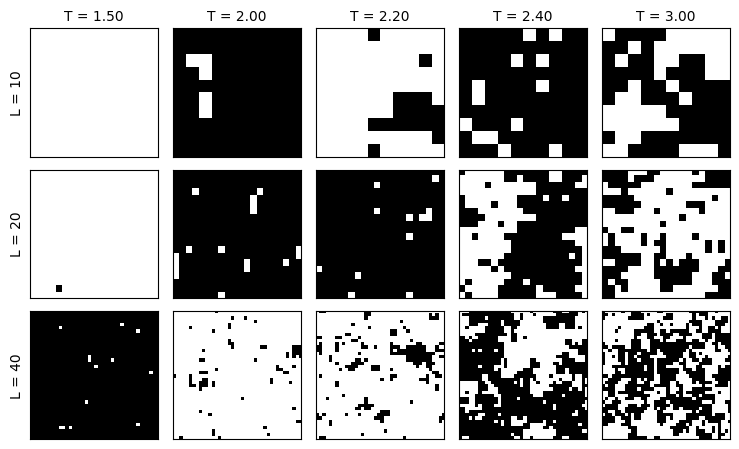

In [7]:
T_show = [1.5, 2.0, 2.2, 2.4, 3.0]
fig, axs = plt.subplots(3, len(T_show), figsize=(7.5, 4.6))
for r, L in enumerate((10, 20, 40)):
    c, Ts = data[L]
    for k, T in enumerate(T_show):
        i = int(np.argmin(np.abs(Ts - T))); a = axs[r, k]
        a.imshow(c[i, 0], cmap="gray", vmin=-1, vmax=1, interpolation="nearest"); a.set_xticks([]); a.set_yticks([])
        if r == 0: a.set_title(f"T = {Ts[i]:.2f}", fontsize=10)
        if k == 0: a.set_ylabel(f"L = {L}", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_Ising_dataset.png", dpi=170, bbox_inches="tight"); plt.show()

## The CNN finds $T_c$ from its confidence

The model and the training are those of **Lab 011**, copied unchanged: two blocks of Conv2D (32 kernels $3\times3$, circular padding, ReLU) and max pooling, a dense layer of 64 ReLU nodes, 2 outputs with softmax, cross-entropy, Adam. Training data: only $T<1.5$ (label 0, ordered) and $T>3$ (label 1, disordered). After training we predict at every temperature. The **confidence** of a prediction is $\max(p_0, p_1)$; its average is lowest where the network is least sure. A second estimate of $T_c$ is the temperature where $\langle p_1\rangle_T$ crosses $1/2$. We train three times (seeds 0, 1, 2) on $L = 40$.

In [8]:
T_MIN, T_MAX = 1.5, 3.0

def make_training_set(configs, temperatures, rng, val_fraction=0.2):
    low, high = temperatures < T_MIN, temperatures > T_MAX
    X = np.concatenate([configs[low].reshape(-1, *configs.shape[2:]), configs[high].reshape(-1, *configs.shape[2:])])
    y = np.concatenate([np.zeros(configs[low].shape[0] * configs.shape[1]), np.ones(configs[high].shape[0] * configs.shape[1])])
    perm = rng.permutation(len(y))
    X, y = X[perm], y[perm]
    n_val = int(val_fraction * len(y))
    to_t = lambda a: torch.tensor(a, dtype=torch.float32).unsqueeze(1)   # (n, 1, L, L): one input channel
    return (to_t(X[n_val:]), torch.tensor(y[n_val:], dtype=torch.long),
            to_t(X[:n_val]), torch.tensor(y[:n_val], dtype=torch.long))

class IsingCNN(nn.Module):
    def __init__(self, L, channels=32, hidden=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(channels, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2))
        side = L // 4                                          # two 2x2 poolings
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(channels * side * side, hidden), nn.ReLU(),
                                        nn.Linear(hidden, 2))
    def forward(self, x):
        return self.classifier(self.features(x))               # logits z_0, z_1

def train(model, X_tr, y_tr, X_val, y_val, epochs=5, batch_size=64, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()                            # softmax + categorical cross-entropy
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(y_tr))
        for i in range(0, len(y_tr), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out_tr, out_val = model(X_tr), model(X_val)
            rec = (loss_fn(out_tr, y_tr).item(), (out_tr.argmax(1) == y_tr).float().mean().item(),
                   loss_fn(out_val, y_val).item(), (out_val.argmax(1) == y_val).float().mean().item())
        history.append(rec)
        if verbose:
            print(f"epoch {epoch + 1:2d}: train loss {rec[0]:.2e} acc {rec[1]:.4f} | validation loss {rec[2]:.2e} acc {rec[3]:.4f}")
    return np.array(history)

def predict(model, configs):
    # Softmax probabilities p_1 (disordered) for all configurations: array (temperatures, samples).
    model.eval()
    X = torch.tensor(configs.reshape(-1, 1, *configs.shape[2:]), dtype=torch.float32)
    with torch.no_grad():
        p = torch.cat([torch.softmax(model(X[i:i + 2048]), dim=1)[:, 1] for i in range(0, len(X), 2048)])
    return p.numpy().reshape(configs.shape[:2])

def estimate_Tc(temperatures, p1):
    conf = np.maximum(p1, 1 - p1)
    conf_mean, p1_mean = conf.mean(1), p1.mean(1)
    T_conf = temperatures[np.argmin(conf_mean)]                       # lowest average confidence
    i = np.argmax(p1_mean >= 0.5)                                     # first temperature where <p_1> >= 1/2
    T_cross = temperatures[i - 1] + (0.5 - p1_mean[i - 1]) * (temperatures[i] - temperatures[i - 1]) / (p1_mean[i] - p1_mean[i - 1])
    return conf_mean, p1_mean, T_conf, T_cross

In [9]:
L = 40
cfg, Ts = data[L]
runs = []
for seed in (0, 1, 2):
    torch.manual_seed(seed)
    Xa, ya, Xb, yb = make_training_set(cfg, Ts, np.random.default_rng(seed))
    m = IsingCNN(L); h = train(m, Xa, ya, Xb, yb, epochs=3, verbose=False)
    pp = predict(m, cfg); conf_mean, p1_mean, T_conf, T_cross = estimate_Tc(Ts, pp)
    runs.append((pp, conf_mean, p1_mean, T_conf, T_cross))
    print(f"seed {seed}: validation accuracy {h[-1, 3]:.4f} | T_c from the confidence minimum = {T_conf:.2f} | from <p_1> = 1/2: {T_cross:.3f}")
Tconf = np.array([r[3] for r in runs]); Tcross = np.array([r[4] for r in runs])
print(f"L = {L}: confidence minimum {Tconf.mean():.3f} +- {Tconf.std():.3f};  crossing {Tcross.mean():.3f} +- {Tcross.std():.3f};  exact T_c = {TC:.4f}")

seed 0: validation accuracy 1.0000 | T_c from the confidence minimum = 2.25 | from <p_1> = 1/2: 2.282


seed 1: validation accuracy 1.0000 | T_c from the confidence minimum = 2.25 | from <p_1> = 1/2: 2.249


seed 2: validation accuracy 1.0000 | T_c from the confidence minimum = 2.30 | from <p_1> = 1/2: 2.319
L = 40: confidence minimum 2.267 +- 0.024;  crossing 2.283 +- 0.029;  exact T_c = 2.2692


The figure for the slide (seed 0): on top the temperature bar with the two training windows ($T<1.5$ and $T>3$; the data end at $T=3.5$); below, the confidence of every configuration, coloured by the predicted phase, and the average confidence.

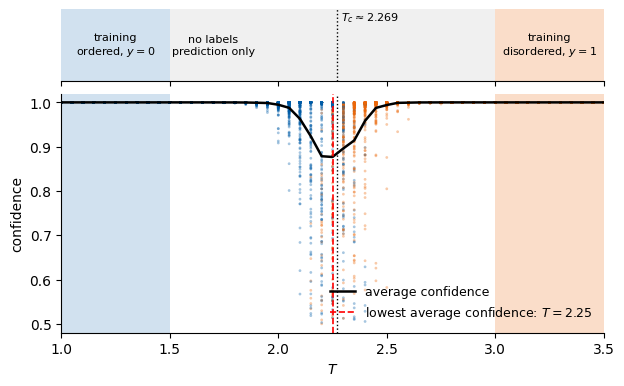

In [10]:
pp, conf_mean, p1_mean, T_conf, T_cross = runs[0]
conf = np.maximum(pp, 1 - pp)
fig, (axb, ax) = plt.subplots(2, 1, figsize=(7.0, 4.2), sharex=True, gridspec_kw=dict(height_ratios=[0.9, 3], hspace=0.08))
# temperature bar: training windows and the region without labels
for a in (axb, ax):
    a.axvspan(1.0, 1.5, color=blue, alpha=0.18, lw=0); a.axvspan(3.0, 3.5, color=orange, alpha=0.22, lw=0)
axb.axvspan(1.5, 3.0, color="#8A8A8A", alpha=0.12, lw=0)
axb.text(1.25, 0.5, "training\nordered, $y=0$", ha="center", va="center", fontsize=8)
axb.text(2.25 - 0.55, 0.5, "no labels\nprediction only", ha="center", va="center", fontsize=8)
axb.text(3.25, 0.5, "training\ndisordered, $y=1$", ha="center", va="center", fontsize=8)
axb.set_yticks([]); axb.set_ylim(0, 1)
for s_ in ["top", "right", "left"]: axb.spines[s_].set_visible(False)
for k, T in enumerate(Ts):
    ax.scatter(np.full(conf.shape[1], T), conf[k], s=4, c=np.where(pp[k] > 0.5, orange, blue), alpha=0.35, lw=0)
ax.plot(Ts, conf_mean, "k-", lw=1.8, label="average confidence")
for a in (axb, ax): a.axvline(TC, color="k", ls=":", lw=1)
axb.text(TC + 0.02, 0.85, r"$T_c \approx 2.269$", fontsize=8)
ax.axvline(T_conf, color="r", ls="--", lw=1.2, label=rf"lowest average confidence: $T = {T_conf:.2f}$")
ax.set_xlim(1.0, 3.5); ax.set_ylim(0.48, 1.02); ax.set_xlabel("$T$"); ax.set_ylabel("confidence")
ax.legend(frameon=False, fontsize=9, loc="lower right")
for s_ in ["top", "right"]: ax.spines[s_].set_visible(False)
plt.savefig(f"{OUT}/gen_Ising_confidence_vs_T.png", dpi=170, bbox_inches="tight"); plt.show()